In [ ]:
!pip install -q gdown
!pip install -q optuna

In [ ]:
import os
import random
import json as _json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import optuna
import joblib

from google.colab import drive

# Reproducibility seeds
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
print(f"Random seeds fixed to {RANDOM_SEED}")


Random seeds fixed to 42


In [ ]:
# Mount Google Drive for data persistence
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# Create persistent output directory on Drive
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens"
os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
print(f"Drive mounted. Outputs will be saved to: {DRIVE_OUTPUT_DIR}")


Drive mounted. Outputs will be saved to: /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens


In [ ]:
!gdown --folder "https://drive.google.com/drive/folders/1fwACM6i6uVGFkTlJKSlqVhizzgrHl_gY?usp=sharing" -O /content/data

Retrieving folder contents
Retrieving folder 1KBZMgBr4x1XoNi_UqfNltlRyaRU2ged1 collected_Abdelrahman
Processing file 1cQ5ggKfjhH38q_09m_ehn_UkkmkyRIeo abdelrahman_20260306_023035.npz
Retrieving folder 1nB9ZjkJp-JZolWccPGVBZh3PcpbfbSHj collected_ayten
Processing file 1N1NevFW77ntOO0W8GhOhVzxh5WoMl-Pc ayten_session_1.npz
Retrieving folder 1zk7e6gcyf8NWjpUm2wn34xkwHDA9xra1 collected_Jarek
Processing file 16mdc4Dh71_mqxTDq39AufD19vgexOUZb Jarek_20260225_012931.npz
Retrieving folder 1m-jWGxgVhSMjGOIo0cAklLZpUfcZHAtj collected_Junhao
Processing file 1uDfRGyGfEipzwO4VGR6VnBsCIejBHeye Junhao_20260303_113554.npz
Retrieving folder 1U9QdDwj-Hc8wd2YK4g2fTz69YQ8QzHiU collected_Kexin
Processing file 1iytRih5T5ibTveSBk9ULXmhuMyqFDSXx kexin_20260224_151043.npz
Processing file 1Y7V_TLnlhyRTd3uGaMKmR0hBb9pVjO7q kexin2_20260305_180229.npz
Retrieving folder 1ARlCLpDxAavKJf0yMh4zrtUv7cwwJyA4 collected_Langyuan
Processing file 1jAkHUMLzIFOKPcI3Y9ACGJLRplpIN-a1 Langyuan_20260303_153145.npz
Retrieving folder 

In [ ]:
os.listdir("/content/data")

['collected_Yingtao',
 'collected_Junhao',
 'README.md',
 'collected_Mohamed',
 'collected_ayten',
 'collected_saba',
 'collected_Abdelrahman',
 'collected_Langyuan',
 'collected_Jarek',
 'collected_Kexin']

In [ ]:
files = sorted([x for x in os.listdir("/content/data") if x.startswith("collected")])
files

['collected_Abdelrahman',
 'collected_Jarek',
 'collected_Junhao',
 'collected_Kexin',
 'collected_Langyuan',
 'collected_Mohamed',
 'collected_Yingtao',
 'collected_ayten',
 'collected_saba']

In [ ]:
len(files)

9

In [ ]:
round(0.7 * len(files))

6

In [ ]:
n_train = round(0.7 * len(files))
n_val   = round(0.2 * len(files))
n_test  = len(files) - n_train - n_val  # guarantee no rounding gap

assert n_test >= 1, "Too few subjects for a test split"
print(f"Splits  train={n_train}  val={n_val}  test={n_test}  total={len(files)}")


Splits  train=6  val=2  test=1  total=9


In [ ]:
# Splitting train Folders

splits_dict = {
    "train": files[:n_train],
    "val": files[n_train:n_train + n_val],
    "test": files[n_train + n_val:]
}

splits_dict

{'train': ['collected_Abdelrahman',
  'collected_Jarek',
  'collected_Junhao',
  'collected_Kexin',
  'collected_Langyuan',
  'collected_Mohamed'],
 'val': ['collected_Yingtao', 'collected_ayten'],
 'test': ['collected_saba']}

In [ ]:
sample = np.load("/content/data/collected_Abdelrahman/abdelrahman_20260306_023035.npz")
sample.keys()

KeysView(NpzFile '/content/data/collected_Abdelrahman/abdelrahman_20260306_023035.npz' with keys: features, labels, feature_names)

In [ ]:
sample_df = pd.DataFrame(sample["features"], columns = sample["feature_names"])
sample_df["label"] = sample["labels"]

sample_df

,ear_left,ear_right,ear_avg,h_gaze,v_gaze,mar,yaw,pitch,roll,s_face,s_eye,gaze_offset,head_deviation,perclos,blink_rate,closure_duration,yawn_duration,label
0,0.560391,0.538766,0.549578,0.427840,0.469075,0.014449,12.692230,-9.688971,3.712468,0.443818,0.818246,0.078508,15.967744,0.000000,0.0,0.0,0.0,1
1,0.559558,0.541406,0.550482,0.428256,0.468239,0.015588,12.645511,-9.627526,3.743285,0.447571,0.818454,0.078460,15.893338,0.000000,0.0,0.0,0.0,1
2,0.558553,0.540523,0.549538,0.428533,0.467423,0.016160,12.752780,-9.647859,3.772911,0.442429,0.818099,0.078542,15.991077,0.000000,0.0,0.0,0.0,1
3,0.556747,0.539919,0.548333,0.429227,0.467582,0.021686,12.905530,-9.671196,3.791946,0.435349,0.821107,0.077845,16.127142,0.000000,0.0,0.0,0.0,1
4,0.559655,0.540666,0.550160,0.431104,0.469387,0.025649,13.028961,-9.652293,3.772249,0.430889,0.831534,0.075391,16.214827,0.000000,0.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15865,0.233675,0.399963,0.316819,0.523889,0.565133,0.012532,13.385919,-29.050816,9.187295,0.000000,0.856022,0.069375,31.986446,0.016667,14.0,0.0,0.0,0
15866,0.244258,0.399374,0.321816,0.516816,0.540131,0.011400,13.890273,-29.292751,9.362760,0.000000,0.941588,0.043512,32.419205,0.016667,14.0,0.0,0.0,0
15867,0.240078,0.379442,0.309760,0.524842,0.585033,0.009899,14.178144,-29.555544,10.016782,0.000000,0.772694,0.088587,32.780327,0.016667,14.0,0.0,0.0,0
15868,0.241285,0.377332,0.309309,0.502717,0.503289,0.020286,15.604496,-28.967426,10.280792,0.000000,0.999427,0.004266,32.903072,0.016667,14.0,0.0,0.0,0


In [ ]:
sample_df["s_eye"].describe()

,s_eye
count,15870.000000
mean,0.714711
std,0.237518
min,0.000000
25%,0.672946
50%,0.785329
75%,0.856573
max,0.999903


In [ ]:
sample_df.columns

Index(['ear_left', 'ear_right', 'ear_avg', 'h_gaze', 'v_gaze', 'mar', 'yaw',
       'pitch', 'roll', 's_face', 's_eye', 'gaze_offset', 'head_deviation',
       'perclos', 'blink_rate', 'closure_duration', 'yawn_duration', 'label'],
      dtype='object')

### 📋 Column Mapping: Live MediaPipe script vs. Saved Dataset (`sample_df`)

| Live Script Variable | Source / Blendshape Key | `sample_df` Target Column | Notes |
| :--- | :--- | :--- | :--- |
| `yaw` | `angles[1]` (Decomposed Matrix) | **`yaw`** | Matches directly |
| `pitch` | `angles[0]` (Decomposed Matrix) | **`pitch`** | Matches directly |
| `roll` | `angles[2]` (Decomposed Matrix) | **`roll`** | Matches directly |
| `blink_left` | `eyeBlinkLeft` | **`ear_left`** | *Inverse Relationship* (High EAR = Open; High Blink = Closed) |
| `blink_right` | `eyeBlinkRight` | **`ear_right`** | *Inverse Relationship* (High EAR = Open; High Blink = Closed) |
| `look_down_l` | `eyeLookDownLeft` | **`v_gaze`** | Contributes to vertical gaze metric |

#### Recommended subsetting slice of features for training:
```python
# If you want to train a model matching only the available features from your live script:
subset_features = ['yaw', 'pitch', 'roll', 'ear_left', 'ear_right']
```

In [ ]:
# Loading entire dataset split (tracking subject folder for GroupKFold)
def load_data(split: str = "train", base_path: str = "/content/data") -> pd.DataFrame:
    _features = ["yaw", "pitch", "roll", "ear_left", "ear_right"]
    dfs = []
    for folder in splits_dict[split]:
        folder_path = os.path.join(base_path, folder)
        for file in sorted(os.listdir(folder_path)):  # sorted for reproducibility
            if file.endswith(".npz"):
                file_path = os.path.join(folder_path, file)
                sample = np.load(file_path)
                sample_df = pd.DataFrame(sample["features"], columns=sample["feature_names"])
                sample_df = sample_df[_features]
                sample_df["label"] = sample["labels"]
                sample_df["subject"] = folder  # track subject identity for GroupKFold
                dfs.append(sample_df)
    if not dfs:
        return pd.DataFrame(columns=_features + ["label", "subject"])
    df = pd.concat(dfs, ignore_index=True)  # single concat — O(n)
    print(f"Successfully loaded {len(df)} rows of {split} data ({df['subject'].nunique()} subjects)")
    return df

train_df = load_data("train")
val_df   = load_data("val")
test_df  = load_data("test")


Successfully loaded 100879 rows of train data (6 subjects)
Successfully loaded 35212 rows of val data (2 subjects)
Successfully loaded 8702 rows of test data (1 subjects)


### Preprocessing
FocusGuard landmark extractions sometimes contain NaN or infinite values when tracking drops. We clean those and scale features for models that require normalization.

In [ ]:
train_df.info(), val_df.info(), test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100879 entries, 0 to 100878
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   yaw        100879 non-null  float32
 1   pitch      100879 non-null  float32
 2   roll       100879 non-null  float32
 3   ear_left   100879 non-null  float32
 4   ear_right  100879 non-null  float32
 5   label      100879 non-null  int64  
 6   subject    100879 non-null  object 
dtypes: float32(5), int64(1), object(1)
memory usage: 3.5+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35212 entries, 0 to 35211
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   yaw        35212 non-null  float32
 1   pitch      35212 non-null  float32
 2   roll       35212 non-null  float32
 3   ear_left   35212 non-null  float32
 4   ear_right  35212 non-null  float32
 5   label      35212 non-null  int64  
 6   subject    35212 non-null 

(None, None, None)

In [ ]:
# Inspect class distribution
print("Train Class Distribution:\n", train_df['label'].value_counts())


Train Class Distribution:
 label
1    56033
0    44846
Name: count, dtype: int64


In [ ]:
# Separate features (X) and target (y)
feature_cols = ["yaw", "pitch", "roll", "ear_left", "ear_right"]

X_train, y_train = train_df[feature_cols], train_df["label"]
X_val,   y_val   = val_df[feature_cols],   val_df["label"]
X_test,  y_test  = test_df[feature_cols],  test_df["label"]


# Combines train + val subjects so cross-validation can rotate across all dev subjects
train_val_df = pd.concat([train_df, val_df], ignore_index=True)
X_train_val  = train_val_df[feature_cols]
y_train_val_raw = train_val_df["label"]
groups_train_val = train_val_df["subject"]

print(f"Dev set (train+val): {len(train_val_df)} rows across {groups_train_val.nunique()} subjects: {sorted(groups_train_val.unique())}")
print(f"Held-out test set  : {len(test_df)} rows across {test_df['subject'].nunique()} subject: {test_df['subject'].unique().tolist()}")


Dev set (train+val): 136091 rows across 8 subjects: ['collected_Abdelrahman', 'collected_Jarek', 'collected_Junhao', 'collected_Kexin', 'collected_Langyuan', 'collected_Mohamed', 'collected_Yingtao', 'collected_ayten']
Held-out test set  : 8702 rows across 1 subject: ['collected_saba']


In [ ]:
# Encode labels
label_encoder = LabelEncoder()
y_train     = label_encoder.fit_transform(y_train)
y_val       = label_encoder.transform(y_val)
y_test      = label_encoder.transform(y_test)
y_train_val = label_encoder.transform(y_train_val_raw)
classes     = [str(c) for c in label_encoder.classes_]

# Feature scaling (fit on dev set to avoid leakage into test)
scaler = StandardScaler()
X_train_val_scaled = scaler.fit_transform(X_train_val)
X_train_scaled     = scaler.transform(X_train)
X_val_scaled       = scaler.transform(X_val)
X_test_scaled      = scaler.transform(X_test)
print(f"Encoded classes: {classes}")


Encoded classes: ['0', '1']


In [ ]:
val_df[["ear_left", "ear_right"]].max(axis=1).round(1).value_counts()

,count
0.5,13635
0.6,6800
0.4,6512
0.2,2334
0.3,2255
0.1,1931
0.7,836
0.8,353
0.9,191
1.3,91


## Using Pure Logic

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score

class Logic:
    """Rule-based focus detector. predict() returns 1 = unfocused, 0 = focused."""

    def __init__(self, yaw_limit=15, pitch_limit=15, eye_closed=0.5, ear_closed=0.5, center=False):
        self.yaw_limit, self.pitch_limit = yaw_limit, pitch_limit
        self.eye_closed, self.ear_closed = eye_closed, ear_closed   # blink score / EAR thresholds
        self.center = center      # True: subtract each subject's median yaw and pitch first

    def predict(self, df):
        yaw, pitch = df["yaw"], df["pitch"]
        if self.center:
            yaw = yaw - yaw.groupby(df["subject"]).transform("median")
            pitch = pitch - pitch.groupby(df["subject"]).transform("median")
        #bad = (yaw.abs() > self.yaw_limit) | (pitch.abs() > self.pitch_limit)
        bad = (yaw.abs() > self.yaw_limit) | (pitch.abs() > self.pitch_limit)
        if "eye" in df:                                   # blink score, high = closed
            bad |= df["eye"] >= self.eye_closed
        elif "ear_left" in df:                            # EAR, low = closed
            bad |= df[["ear_left", "ear_right"]].max(axis=1) > self.ear_closed
        return bad.astype(int).values


def evaluate(y_true, y_pred, plot=True):
    """1 = unfocused is the positive class, so a false positive is a false alarm."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(classification_report(y_true, y_pred, target_names=["focused", "unfocused"], digits=3))
    print(f"accuracy          {accuracy_score(y_true, y_pred):.3f}")
    print(f"balanced accuracy {balanced_accuracy_score(y_true, y_pred):.3f}")
    print(f"false positive rate {fp / (fp + tn):.3f}   (focused flagged as unfocused)")
    print(f"false negative rate {fn / (fn + tp):.3f}   (unfocused missed)")
    if plot:
        cm = np.array([[tn, fp], [fn, tp]])
        plt.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
        plt.xticks([0, 1], ["pred focused", "pred unfocused"]); plt.yticks([0, 1], ["focused", "unfocused"])
        plt.title("Confusion matrix"); plt.show()

In [ ]:
# val_df.value_counts("label")

In [ ]:
# pred = Logic(center=True).predict(val_df)      # FocusGuard: EAR columns, no calibration
# evaluate(val_df["label"], pred)

## Train & Compare Multiple Models
We benchmark four diverse architectures:
- Logistic Regression (Linear baseline, highly interpretable)
- Random Forest (Tree-based ensemble, non-linear)
- HistGradientBoosting (Fast gradient-boosted trees, similar to LightGBM/XGBoost)
- Multi-Layer Perceptron (MLP) (Small neural network)

In [ ]:
# Define baseline models
# Format: (classifier, x_dev, x_train, x_val, x_test)
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
        X_train_val_scaled, X_train_scaled, X_val_scaled, X_test_scaled
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_SEED, n_jobs=-1),
        X_train_val, X_train, X_val, X_test
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(max_iter=100, max_depth=8, random_state=RANDOM_SEED),
        X_train_val, X_train, X_val, X_test
    ),
    "Neural Network (MLP)": (
        MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True, random_state=RANDOM_SEED),
        X_train_val_scaled, X_train_scaled, X_val_scaled, X_test_scaled
    )
}


In [ ]:
results = []
trained_models = {}

# GroupKFold across the development subjects (4 folds = 2 unseen subjects per fold)
n_dev_subjects = groups_train_val.nunique()
n_splits = min(4, n_dev_subjects)
gkf = GroupKFold(n_splits=n_splits)
print(f"Running {n_splits}-fold GroupKFold Cross-Validation across {n_dev_subjects} development subjects...\n")

for name, (clf, x_dev, x_tr, x_v, x_te) in models.items():
    print(f"Evaluating {name}...")

    # Subject-level cross-validation on dev set
    cv_scores = cross_val_score(
        clf, x_dev, y_train_val,
        groups=groups_train_val,
        cv=gkf,
        scoring="f1_macro"
    )
    cv_val_f1 = cv_scores.mean()
    cv_val_std = cv_scores.std()

    # Train on full dev set for final evaluation and deployment
    clf.fit(x_dev, y_train_val)
    trained_models[name] = clf

    # Train performance (fit check)
    tr_preds = clf.predict(x_dev)
    tr_acc   = accuracy_score(y_train_val, tr_preds)
    tr_f1    = f1_score(y_train_val, tr_preds, average="macro")

    # Held-out test evaluation (completely unseen test subject)
    te_preds = clf.predict(x_te)
    te_probs = clf.predict_proba(x_te)[:, 1] if len(classes) == 2 else None
    te_acc   = accuracy_score(y_test, te_preds)
    te_f1    = f1_score(y_test, te_preds, average="macro")
    te_auc   = roc_auc_score(y_test, te_probs) if te_probs is not None else np.nan

    overfit_gap = tr_f1 - cv_val_f1

    results.append({
        "Model":                  name,
        "Train F1":               tr_f1,
        "Val F1":                 cv_val_f1,  # Cross-validated across subject folds
        "Val F1 (Std)":           cv_val_std,
        "Overfit Gap (Tr - Val)": overfit_gap,
        "Test Acc":               te_acc,
        "Test F1":                te_f1,
        "Test AUC":               te_auc,
    })

# Format into clean DataFrame
results_df = pd.DataFrame(results).sort_values(by="Test F1", ascending=False).reset_index(drop=True)

display(
    results_df.style
    .highlight_max(subset=["Val F1", "Test F1"], color="green")
    .format({
        "Train F1": "{:.3f}", "Val F1": "{:.3f}", "Val F1 (Std)": "±{:.3f}",
        "Overfit Gap (Tr - Val)": "{:+.3f}",
        "Test Acc": "{:.3f}", "Test F1": "{:.3f}", "Test AUC": "{:.3f}"
    })
)


Running 4-fold GroupKFold Cross-Validation across 8 development subjects...

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...
Evaluating Neural Network (MLP)...


,Model,Train F1,Val F1,Val F1 (Std),Overfit Gap (Tr - Val),Test Acc,Test F1,Test AUC
0,Gradient Boosting,0.904,0.799,±0.040,+0.105,0.922,0.922,0.973
1,Random Forest,0.902,0.803,±0.035,+0.099,0.918,0.918,0.970
2,Neural Network (MLP),0.907,0.793,±0.037,+0.114,0.879,0.879,0.969
3,Logistic Regression,0.693,0.659,±0.061,+0.034,0.770,0.753,0.690


In [ ]:
# Save ALL baseline models to Google Drive
BASELINE_SCALER_MAP = {
    "Logistic Regression":  True,
    "Random Forest":        False,
    "Gradient Boosting":    False,
    "Neural Network (MLP)": True,
}

baseline_dir = os.path.join(DRIVE_OUTPUT_DIR, "baseline")
os.makedirs(baseline_dir, exist_ok=True)

print("\nSaving baseline models to Drive...")
for model_name, model_obj in trained_models.items():
    safe_name = model_name.replace(" ", "_").replace("(", "").replace(")", "")
    save_path = os.path.join(baseline_dir, f"{safe_name}.pkl")
    joblib.dump(model_obj, save_path)
    needs = BASELINE_SCALER_MAP[model_name]
    tag = "needs scaler" if needs else "no scaler needed"
    print(f"  [{tag:>17}]  {model_name:<30} -> {save_path}")

baseline_csv = os.path.join(baseline_dir, "baseline_results.csv")
results_df.to_csv(baseline_csv, index=False)
print(f"  Results CSV -> {baseline_csv}")
print("Done.")


Saving baseline models to Drive...
  [     needs scaler]  Logistic Regression            -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Logistic_Regression.pkl
  [ no scaler needed]  Random Forest                  -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Random_Forest.pkl
  [ no scaler needed]  Gradient Boosting              -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Gradient_Boosting.pkl
  [     needs scaler]  Neural Network (MLP)           -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Neural_Network_MLP.pkl
  Results CSV -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/baseline_results.csv
Done.


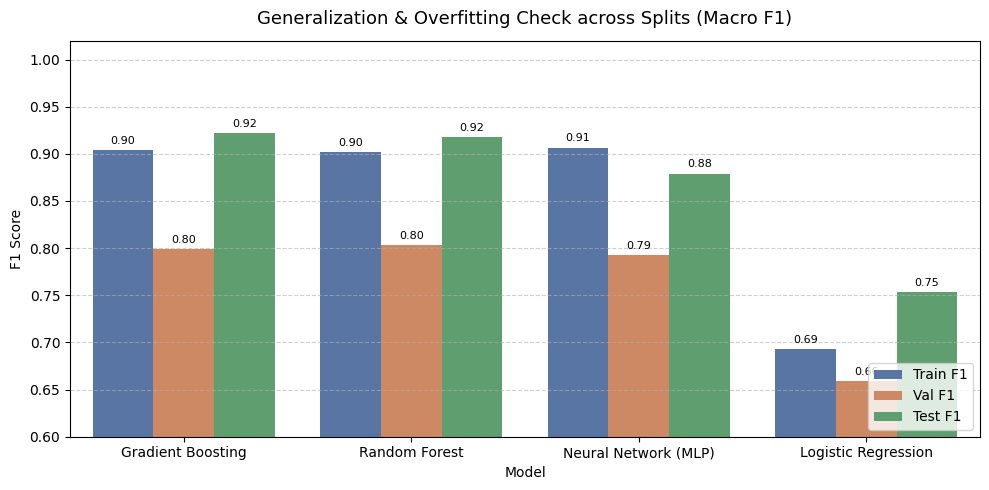

In [ ]:
# Melt dataframe for easy seaborn plotting
plot_df = results_df.melt(
    id_vars=["Model"],
    value_vars=["Train F1", "Val F1", "Test F1"],
    var_name="Split",
    value_name="F1 Score"
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, x="Model", y="F1 Score", hue="Split", palette=["#4c72b0", "#dd8452", "#55a868"])
plt.title("Generalization & Overfitting Check across Splits (Macro F1)", fontsize=13, pad=12)
plt.ylim(0.6, 1.02)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')

# Add values above bars
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

### Hyperparameter Tuning

In [ ]:
# OBJECTIVE FUNCTIONS (Evaluated via GroupKFold)
cv_tuning = GroupKFold(n_splits=min(4, groups_train_val.nunique()))

# Gradient Boosting Objective
def objective_gb(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_iter": trial.suggest_int("max_iter", 60, 180, step=20),
        "max_depth": trial.suggest_int("max_depth", 3, 9),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 40),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 10.0, log=True),
        "random_state": RANDOM_SEED
    }
    clf = HistGradientBoostingClassifier(**params)
    scores = cross_val_score(
        clf, X_train_val, y_train_val,
        groups=groups_train_val, cv=cv_tuning, scoring="f1_macro"
    )
    return scores.mean()

# Random Forest Objective
def objective_rf(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 150, step=25),
        "max_depth": trial.suggest_int("max_depth", 4, 14),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 6),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "random_state": RANDOM_SEED,
        "n_jobs": -1
    }
    clf = RandomForestClassifier(**params)
    scores = cross_val_score(
        clf, X_train_val, y_train_val,
        groups=groups_train_val, cv=cv_tuning, scoring="f1_macro"
    )
    return scores.mean()

# Neural Network (MLP) Objective — with leak-free fold scaling
def objective_mlp(trial):
    hidden_options = [(32,), (64,), (64, 32), (128, 64)]
    idx = trial.suggest_int("hidden_idx", 0, len(hidden_options) - 1)
    params = {
        "hidden_layer_sizes": hidden_options[idx],
        "activation": trial.suggest_categorical("activation", ["relu", "tanh"]),
        "alpha": trial.suggest_float("alpha", 1e-4, 1.0, log=True),
        "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-3, 1e-2, log=True),
        "max_iter": 200,
        "early_stopping": True,
        "random_state": RANDOM_SEED
    }
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(**params))
    ])
    scores = cross_val_score(
        pipe, X_train_val, y_train_val,
        groups=groups_train_val, cv=cv_tuning, scoring="f1_macro"
    )
    return scores.mean()

# Logistic Regression Objective — with leak-free fold scaling
def objective_lr(trial):
    params = {
        "C": trial.suggest_float("C", 0.01, 100.0, log=True),
        "max_iter": 1000,
        "random_state": RANDOM_SEED
    }
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(**params))
    ])
    scores = cross_val_score(
        pipe, X_train_val, y_train_val,
        groups=groups_train_val, cv=cv_tuning, scoring="f1_macro"
    )
    return scores.mean()


In [ ]:
# Suppress debug logs from optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# RUN GROUP-KFOLD OPTIMIZATION STUDIES
# 25 trials * 4 subject-folds = 100 evaluations per architecture
studies = {
    "Gradient Boosting":    (objective_gb, 25),
    "Random Forest":        (objective_rf, 25),
    "Neural Network (MLP)": (objective_mlp, 25),
    "Logistic Regression":  (objective_lr, 25)
}

best_params_dict = {}

for name, (obj_func, n_trials) in studies.items():
    print(f"\n--> Optimizing {name} ({n_trials} trials, {cv_tuning.n_splits}-fold GroupKFold)...")
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    study.optimize(obj_func, n_trials=n_trials, show_progress_bar=True)
    best_params_dict[name] = study.best_params
    print(f"    ✓ Best Cross-Validated Macro F1: {study.best_value:.4f}")

# Build instantiated models with best params
mlp_best_params = best_params_dict["Neural Network (MLP)"].copy()
hidden_options = [(32,), (64,), (64, 32), (128, 64)]
mlp_best_params["hidden_layer_sizes"] = hidden_options[mlp_best_params.pop("hidden_idx")]
mlp_best_params["max_iter"] = 300
mlp_best_params["early_stopping"] = True
mlp_best_params["random_state"] = RANDOM_SEED

tuned_models = {
    "Gradient Boosting (Tuned)": (
        HistGradientBoostingClassifier(**best_params_dict["Gradient Boosting"], random_state=RANDOM_SEED),
        X_train_val, X_train, X_val, X_test
    ),
    "Random Forest (Tuned)": (
        RandomForestClassifier(**best_params_dict["Random Forest"], random_state=RANDOM_SEED, n_jobs=-1),
        X_train_val, X_train, X_val, X_test
    ),
    "Neural Network (Tuned)": (
        MLPClassifier(**mlp_best_params),
        X_train_val_scaled, X_train_scaled, X_val_scaled, X_test_scaled
    ),
    "Logistic Regression (Tuned)": (
        LogisticRegression(**best_params_dict["Logistic Regression"], max_iter=1000, random_state=RANDOM_SEED),
        X_train_val_scaled, X_train_scaled, X_val_scaled, X_test_scaled
    )
}



--> Optimizing Gradient Boosting (25 trials, 4-fold GroupKFold)...


  0%|          | 0/25 [00:00<?, ?it/s]

    ✓ Best Cross-Validated Macro F1: 0.8088

--> Optimizing Random Forest (25 trials, 4-fold GroupKFold)...


  0%|          | 0/25 [00:00<?, ?it/s]

    ✓ Best Cross-Validated Macro F1: 0.8148

--> Optimizing Neural Network (MLP) (25 trials, 4-fold GroupKFold)...


  0%|          | 0/25 [00:00<?, ?it/s]

    ✓ Best Cross-Validated Macro F1: 0.8127

--> Optimizing Logistic Regression (25 trials, 4-fold GroupKFold)...


  0%|          | 0/25 [00:00<?, ?it/s]

    ✓ Best Cross-Validated Macro F1: 0.6589


In [ ]:
final_results = []
trained_objects = {}

for name, (clf, x_dev, x_tr, x_v, x_te) in tuned_models.items():
    # 1. GroupKFold CV evaluation across development subjects
    cv_scores = cross_val_score(
        clf, x_dev, y_train_val,
        groups=groups_train_val,
        cv=cv_tuning,
        scoring="f1_macro"
    )
    v_f1  = cv_scores.mean()
    v_std = cv_scores.std()

    # 2. Fit on full development set for maximum generalization
    clf.fit(x_dev, y_train_val)
    trained_objects[name] = clf

    tr_preds = clf.predict(x_dev)
    tr_f1    = f1_score(y_train_val, tr_preds, average="macro")

    # 3. Evaluate on held-out unseen test subject
    te_preds = clf.predict(x_te)
    te_f1    = f1_score(y_test, te_preds, average="macro")
    te_acc   = accuracy_score(y_test, te_preds)
    te_probs = clf.predict_proba(x_te)[:, 1] if len(classes) == 2 else None
    te_auc   = roc_auc_score(y_test, te_probs) if te_probs is not None else np.nan

    final_results.append({
        "Model":                  name,
        "Train F1":               tr_f1,
        "Val F1":                 v_f1,  # GroupKFold CV mean
        "Val F1 (Std)":           v_std,
        "Overfit Gap (Tr - Val)": tr_f1 - v_f1,
        "Test Acc":               te_acc,
        "Test F1":                te_f1,
        "Test AUC":               te_auc,
    })

# Format and display
final_df = (
    pd.DataFrame(final_results)
    .sort_values(by="Test F1", ascending=False)
    .reset_index(drop=True)
)
display(
    final_df.style
    .highlight_max(subset=["Val F1", "Test F1"], color="green")
    .format({
        "Train F1": "{:.3f}", "Val F1": "{:.3f}", "Val F1 (Std)": "±{:.3f}",
        "Overfit Gap (Tr - Val)": "{:+.3f}",
        "Test Acc": "{:.3f}", "Test F1": "{:.3f}", "Test AUC": "{:.3f}"
    })
)



,Model,Train F1,Val F1,Val F1 (Std),Overfit Gap (Tr - Val),Test Acc,Test F1,Test AUC
0,Neural Network (Tuned),0.853,0.812,±0.027,+0.041,0.960,0.960,0.985
1,Gradient Boosting (Tuned),0.873,0.809,±0.023,+0.064,0.941,0.941,0.974
2,Random Forest (Tuned),0.855,0.815,±0.014,+0.040,0.928,0.928,0.962
3,Logistic Regression (Tuned),0.693,0.659,±0.061,+0.034,0.770,0.753,0.690


In [ ]:
# Deployment scaler map
TUNED_SCALER_MAP = {
    "Gradient Boosting (Tuned)":    False,
    "Random Forest (Tuned)":        False,
    "Neural Network (Tuned)":       True,
    "Logistic Regression (Tuned)":  True,
}

# Save ALL tuned models + scaler + manifest to Google Drive
tuned_dir = os.path.join(DRIVE_OUTPUT_DIR, "tuned")
os.makedirs(tuned_dir, exist_ok=True)

print("\nSaving tuned models to Drive...")
manifest = {}
for model_name, model_obj in trained_objects.items():
    safe_name = model_name.replace(" ", "_").replace("(", "").replace(")", "")
    save_path = os.path.join(tuned_dir, f"{safe_name}.pkl")
    joblib.dump(model_obj, save_path)
    needs = TUNED_SCALER_MAP[model_name]
    tag   = "needs scaler" if needs else "no scaler needed"
    print(f"  [{tag:>17}]  {model_name:<35} -> {save_path}")
    manifest[model_name] = {
        "file":         save_path,
        "needs_scaler": needs,
        "scaler_file":  os.path.join(DRIVE_OUTPUT_DIR, "focuslens_scaler.pkl") if needs else None,
    }

# Save shared scaler (fitted on full dev set)
scaler_path = os.path.join(DRIVE_OUTPUT_DIR, "focuslens_scaler.pkl")
joblib.dump(scaler, scaler_path)
print(f"\n  Scaler -> {scaler_path}")

# Save results CSV
results_path = os.path.join(tuned_dir, "tuned_results.csv")
final_df.to_csv(results_path, index=False)
print(f"  Results CSV -> {results_path}")

# Save deployment manifest (JSON)
manifest_path = os.path.join(DRIVE_OUTPUT_DIR, "deployment_manifest.json")
with open(manifest_path, "w") as _f:
    _json.dump(manifest, _f, indent=2)
print(f"  Manifest -> {manifest_path}")

# Champion model shortcut
col_f1 = "Test F1"
best_model_name = final_df.iloc[0]["Model"]
best_model_obj  = trained_objects[best_model_name]
champion_path   = os.path.join(DRIVE_OUTPUT_DIR, "best_focuslens_classifier.pkl")
joblib.dump(best_model_obj, champion_path)

print(f"\nChampion Model : {best_model_name!r}  (Test F1: {final_df.iloc[0][col_f1]:.3f})")
print(f"Champion file  -> {champion_path}")

# Deployment guide
print("\n" + "="*60)
print("DEPLOYMENT GUIDE — Scaler requirements")
print("="*60)
print(f"Shared scaler : {scaler_path}")
print()
for model_name, info in manifest.items():
    status = "YES — apply scaler.transform(X) before predict()" if info["needs_scaler"] \
             else "NO  — pass raw feature array directly to predict()"
    print(f"  {model_name}")
    print(f"    Needs scaler: {status}")
    print()
print("Feature order expected by all models:", ["yaw", "pitch", "roll", "ear_left", "ear_right"])
print("="*60)



Saving tuned models to Drive...
  [ no scaler needed]  Gradient Boosting (Tuned)           -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Gradient_Boosting_Tuned.pkl
  [ no scaler needed]  Random Forest (Tuned)               -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Random_Forest_Tuned.pkl
  [     needs scaler]  Neural Network (Tuned)              -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Neural_Network_Tuned.pkl
  [     needs scaler]  Logistic Regression (Tuned)         -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Logistic_Regression_Tuned.pkl

  Scaler -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/focuslens_scaler.pkl
  Results CSV -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/tuned_results.csv
  Manifest -> /content/drive/MyDrive/AIMS Courses/Block 03 - Vi

### Feature Importance Analysis
To determine which features matter most, we evaluate both:
Tree Gini Importance (how much the tree splits relied on each feature).
Permutation Importance on Held-Out Test Data (how much the test score drops when that feature is randomly shuffled—this proves true generalization across unseen individuals).

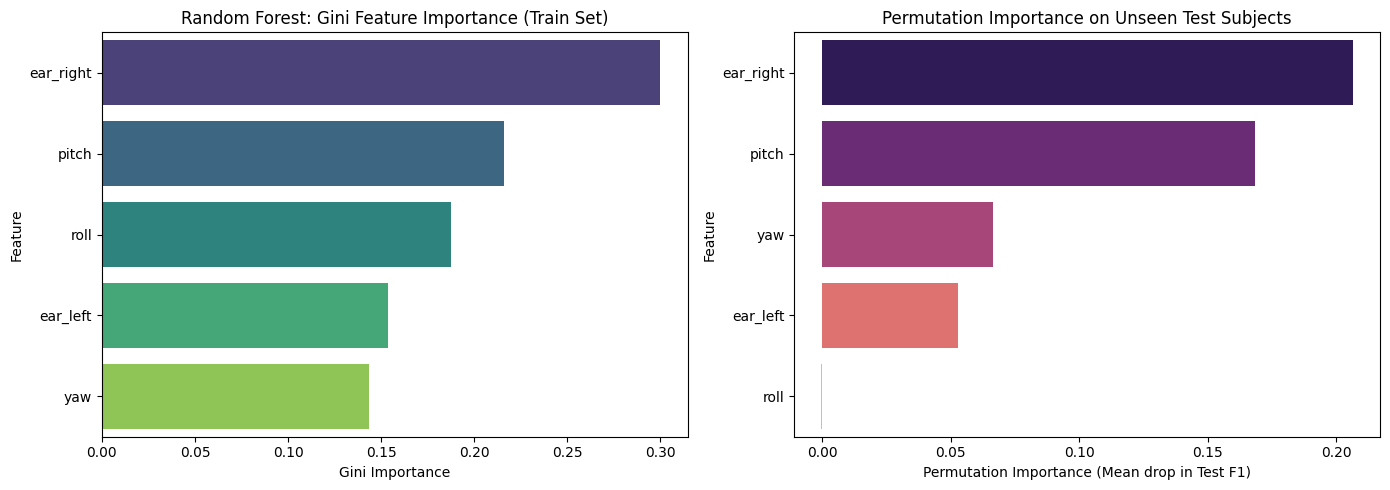


--- Permutation Feature Ranking on Held-Out Test Data ---
ear_right   : Mean Drop in F1 = 0.2066
pitch       : Mean Drop in F1 = 0.1683
yaw         : Mean Drop in F1 = 0.0664
ear_left    : Mean Drop in F1 = 0.0527
roll        : Mean Drop in F1 = -0.0005


In [ ]:
# Best tree model (Random Forest) — tuned version
rf_model = trained_objects.get(
    "Random Forest (Tuned)",
    trained_objects.get("Random Forest", list(trained_objects.values())[0])
)

# Gini / MDI Importance
rf_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Gini Importance": rf_model.feature_importances_
}).sort_values("Gini Importance", ascending=False)

# Permutation Importance on Test Set
perm_col = "Permutation Importance (Mean drop in Test F1)"
perm_result = permutation_importance(
    rf_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_SEED, scoring="f1_macro"
)
perm_df = pd.DataFrame({
    "Feature": feature_cols,
    perm_col: perm_result.importances_mean,
    "Std":    perm_result.importances_std,
}).sort_values(perm_col, ascending=False)

# Plotting (hue= suppresses seaborn v0.14+ palette deprecation warning)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=rf_importance, x="Gini Importance", y="Feature",
    hue="Feature", palette="viridis", ax=axes[0], legend=False
)

axes[0].set_title("Random Forest: Gini Feature Importance (Train Set)")
sns.barplot(
    data=perm_df, x=perm_col, y="Feature",
    hue="Feature", palette="magma", ax=axes[1], legend=False
)
axes[1].set_title("Permutation Importance on Unseen Test Subjects")
plt.tight_layout()
plt.show()

print("\n--- Permutation Feature Ranking on Held-Out Test Data ---")
feat_col = "Feature"
for _, row in perm_df.iterrows():
    print(f"{row[feat_col]:<12}: Mean Drop in F1 = {row[perm_col]:.4f}")


 Confusion Matrix on the Held-Out Test Person

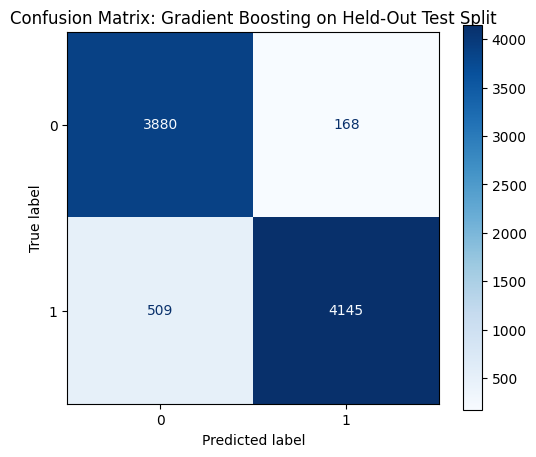

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_clf = trained_models[best_model_name]
x_test_eval = models[best_model_name][-1]  # test split is the last element

test_preds = best_clf.predict(x_test_eval)

cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title(f"Confusion Matrix: {best_model_name} on Held-Out Test Split")
plt.show()


In [ ]:
best_clf.feature_names_in_

array(['yaw', 'pitch', 'roll', 'ear_left', 'ear_right'], dtype=object)

In [ ]:
best_clf.classes_

array([0, 1])

In [ ]:
!python --version

Python 3.13.18


In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1
